# P6. Selección de características con algoritmo genético paralelo

# PARTE 1. Importación de librerías y configuración
1.1. Importar las librerías

Las librerías nos permitirán manipular los datos, realizar cálculos, construir el algoritmo genético, entrenar modelos y ejecutar procesos en paralelo

In [1]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt

# Algoritmos y evaluación de modelos
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Carga de conjuntos de datos
from sklearn.datasets import fetch_openml

# Procesamiento paralelo
from joblib import Parallel, delayed

# Administración de procesos y tiempos
import multiprocessing
import time
import os
import platform

# Reproducibilidad
import random

# Manejo de advertencias
import warnings
warnings.filterwarnings("ignore")

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


1.2. Configuración de parámetros generales

En esta sección estableceremos los parámetros que utilizaremos durante el proyecto.

In [2]:
# Semilla principal para reproducibilidad
SEED = 42

np.random.seed(SEED)
random.seed(SEED)

# Parámetros del algoritmo genético
TAMANO_POBLACION = 12
NUM_GENERACIONES = 10
PROB_MUTACION = 0.01
TAMANO_TORNEO = 3
ELITISMO = 2

# Parámetros de experimentación
NUM_REPETICIONES = 3
NUM_PROCESOS = [1, 2, 4, 8]

print("Configuración establecida correctamente.")

Configuración establecida correctamente.


SEED	Permite reproducir los experimentos.

TAMANO_POBLACION	Cantidad de soluciones que tendrá cada generación.

NUM_GENERACIONES	Número de iteraciones del algoritmo genético.

PROB_MUTACION	Probabilidad de modificar una característica.

TAMANO_TORNEO	Número de individuos que participan en cada torneo.

ELITISMO	Cantidad de mejores individuos que pasan a la siguiente generación.

NUM_REPETICIONES	Veces que repetiremos cada experimento.

NUM_PROCESOS	Cantidad de procesos que utilizaremos para evaluar el paralelismo.

1.3. Identificación del hardware

Es importante conocer las características del equipo donde ejecutaremos las pruebas, porque después analizaremos el rendimiento del procesamiento paralelo.

In [3]:
# Información del sistema
print("INFORMACIÓN DEL HARDWARE")
print("-------------------------------")

print("Sistema operativo:", platform.system())
print("Procesador:", platform.processor())
print("Arquitectura:", platform.machine())

# Núcleos lógicos disponibles
nucleos = multiprocessing.cpu_count()

print("Núcleos lógicos disponibles:", nucleos)

# Información de memoria RAM
try:
    import psutil

    memoria = psutil.virtual_memory()

    print("Memoria RAM total:",
          round(memoria.total / (1024 ** 3), 2), "GB")

except ImportError:
    print("Para consultar la RAM instala psutil.")

INFORMACIÓN DEL HARDWARE
-------------------------------
Sistema operativo: Linux
Procesador: 
Arquitectura: x86_64
Núcleos lógicos disponibles: 12
Memoria RAM total: 22.18 GB


In [4]:
!lscpu

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             48 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      12
  On-line CPU(s) list:       0-11
Vendor ID:                   AuthenticAMD
  Model name:                AMD Ryzen 5 7535HS with Radeon Graphics
    CPU family:              25
    Model:                   68
    Thread(s) per core:      2
    Core(s) per socket:      6
    Socket(s):               1
    Stepping:                1
    Frequency boost:         enabled
    CPU(s) scaling MHz:      66%
    CPU max MHz:             4604.7568
    CPU min MHz:             416.0930
    BogoMIPS:                6587.55
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ht s
                             yscall nx mmxext fxsr_opt pdpe1gb rdtscp lm constan
                      

# PARTE 2. Carga y exploración del conjunto de datos Madelon


Ahora vamos a trabajar con el conjunto de datos que utilizaremos durante todo el proyecto.

¿Qué es Madelon?

Es un conjunto de datos diseñado para problemas de selección de características. Contiene:
- 500 características predictoras.
- 20 características relevantes.
- 480 características irrelevantes.
- Una variable objetivo que identifica dos clases.

2.1. Descargar el conjunto de datos


In [5]:
# Descargar el conjunto de datos Madelon
datos = fetch_openml(
    name="madelon",
    version=1,
    as_frame=True,
    parser="auto"
)

# Separar características y variable objetivo
X = datos.data
y = datos.target.astype(int)

print("Conjunto de datos cargado correctamente.")

Conjunto de datos cargado correctamente.


2.2. Consultar las dimensiones

In [6]:
print("DIMENSIONES DEL CONJUNTO DE DATOS")
print("----------------------------------")

print("Número de registros:", X.shape[0])
print("Número de características:", X.shape[1])
print("Número de clases:", y.nunique())

DIMENSIONES DEL CONJUNTO DE DATOS
----------------------------------
Número de registros: 2600
Número de características: 500
Número de clases: 2


2.3. Visualizar los primeros registros

In [7]:
# Mostrar los primeros cinco registros
X.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V491,V492,V493,V494,V495,V496,V497,V498,V499,V500
0,485,477,537,479,452,471,491,476,475,473,...,477,481,477,485,511,485,481,479,475,496
1,483,458,460,487,587,475,526,479,485,469,...,463,478,487,338,513,486,483,492,510,517
2,487,542,499,468,448,471,442,478,480,477,...,487,481,492,650,506,501,480,489,499,498
3,480,491,510,485,495,472,417,474,502,476,...,491,480,474,572,454,469,475,482,494,461
4,484,502,528,489,466,481,402,478,487,468,...,488,479,452,435,486,508,481,504,495,511


2.4. Revisar la variable objetivo

In [8]:
print("DISTRIBUCIÓN DE CLASES")
print("----------------------")

print(y.value_counts())

DISTRIBUCIÓN DE CLASES
----------------------
Class
2    1300
1    1300
Name: count, dtype: int64


2.5. Verificar valores faltantes

In [9]:
# Contar valores nulos
valores_nulos = X.isnull().sum().sum()

print("Valores faltantes:", valores_nulos)

Valores faltantes: 0


In [10]:
# Información del conjunto de datos
print("INFORMACIÓN DE MADELON")
print("----------------------------")

print("Nombre:", datos.details.get("name"))
print("Versión:", datos.details.get("version"))
print("URL:", datos.url)

print("\nDIMENSIONES")
print("X:", X.shape)
print("y:", y.shape)

print("\nDISTRIBUCIÓN DE CLASES")
print(y.value_counts().sort_index())

INFORMACIÓN DE MADELON
----------------------------
Nombre: madelon
Versión: 1
URL: https://www.openml.org/d/1485

DIMENSIONES
X: (2600, 500)
y: (2600,)

DISTRIBUCIÓN DE CLASES
Class
1    1300
2    1300
Name: count, dtype: int64


¿Qué significa esto para nuestro proyecto?
Tenemos 500 características y queremos que el algoritmo genético encuentre una combinación reducida que permita clasificar correctamente los registros.

La distribución equilibrada es favorable porque ambas clases tienen la misma cantidad de registros.

# PARTE 3. Preparación y limpieza de los datos

En esta sección revisaremos que los datos estén listos para trabajar con el algoritmo genético.

3.1. Verificar los tipos de datos

In [11]:
# Revisar los tipos de datos
print("TIPOS DE DATOS")
print("----------------------")

print(X.dtypes.value_counts())

print("\nTipo de variable objetivo:")
print(y.dtype)

TIPOS DE DATOS
----------------------
int64    500
Name: count, dtype: int64

Tipo de variable objetivo:
int64


3.2. Verificar valores faltantes

In [12]:
# Revisar valores nulos
print("VALORES FALTANTES")
print("----------------------")

print("Valores faltantes en X:", X.isnull().sum().sum())
print("Valores faltantes en y:", y.isnull().sum())

VALORES FALTANTES
----------------------
Valores faltantes en X: 0
Valores faltantes en y: 0


3.3. Verificar registros duplicados

In [13]:
# Identificar registros duplicados
duplicados = X.duplicated().sum()

print("REGISTROS DUPLICADOS")
print("----------------------")
print("Cantidad de registros duplicados:", duplicados)

REGISTROS DUPLICADOS
----------------------
Cantidad de registros duplicados: 0


3.4. Revisar estadísticas descriptiva

In [14]:
# Obtener estadísticas descriptivas
X.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V491,V492,V493,V494,V495,V496,V497,V498,V499,V500
count,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,...,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000,2600.000000
mean,481.742308,483.551154,509.338846,483.364615,500.925769,479.351923,480.488462,476.569615,487.016154,478.806538,...,482.255000,478.803462,486.250769,497.734615,493.812308,510.731538,478.151154,483.157308,508.436538,490.588077
std,6.312905,30.338955,38.798710,8.943204,41.356829,6.896949,40.428218,1.391642,15.277242,7.308349,...,20.857658,4.034889,23.682591,127.455585,34.883461,37.701112,5.863052,13.607801,37.030636,25.926791
min,462.000000,377.000000,370.000000,453.000000,360.000000,459.000000,334.000000,471.000000,430.000000,455.000000,...,407.000000,463.000000,391.000000,103.000000,368.000000,353.000000,457.000000,435.000000,363.000000,403.000000
25%,478.000000,464.000000,484.000000,477.000000,474.000000,475.000000,453.000000,476.000000,477.000000,474.000000,...,468.000000,476.000000,471.000000,405.750000,470.000000,486.000000,474.000000,474.000000,483.000000,473.000000
50%,482.000000,484.000000,509.000000,483.000000,500.000000,479.000000,481.000000,477.000000,487.000000,479.000000,...,482.000000,479.000000,486.000000,505.500000,493.000000,510.000000,478.000000,483.000000,508.000000,491.000000
75%,486.000000,504.000000,535.000000,489.000000,527.000000,484.000000,507.000000,477.000000,497.000000,484.000000,...,496.000000,481.000000,502.000000,586.250000,517.000000,536.000000,482.000000,492.000000,533.000000,508.000000
max,503.000000,610.000000,654.000000,519.000000,688.000000,505.000000,611.000000,482.000000,547.000000,505.000000,...,549.000000,497.000000,571.000000,920.000000,615.000000,661.000000,500.000000,535.000000,644.000000,593.000000


3.5. Visualizar la distribución de clases

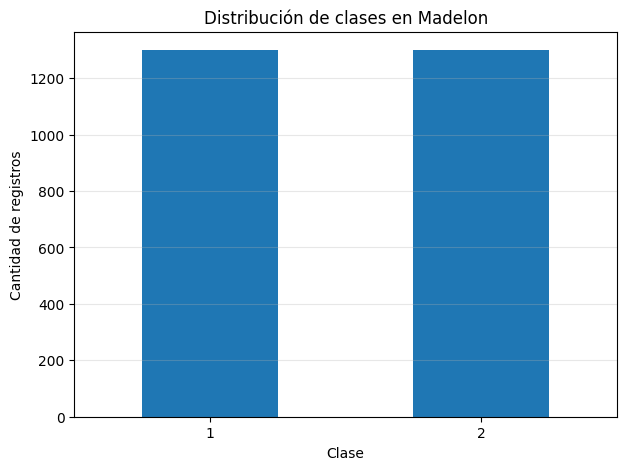

In [15]:
# Gráfica de distribución de clases
plt.figure(figsize=(7, 5))

y.value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribución de clases en Madelon")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

3.6. Confirmar las dimensiones finales

In [16]:
print("RESUMEN DEL CONJUNTO DE DATOS")
print("-----------------------------")

print("Registros:", X.shape[0])
print("Características:", X.shape[1])
print("Clases:", y.nunique())

print("\nPreparación inicial completada.")

RESUMEN DEL CONJUNTO DE DATOS
-----------------------------
Registros: 2600
Características: 500
Clases: 2

Preparación inicial completada.


# PARTE 4. División de los datos

Ahora dividiremos Madelon en tres conjuntos:

Entrenamiento	60 %	Entrenar los modelos.

Validación	20 %	Evaluar las combinaciones de características del algoritmo genético.

Prueba	20 %	Medir el rendimiento final.

4.1. Primera división: entrenamiento y conjunto temporal

In [17]:
# Primera división: 60% entrenamiento y 40% temporal

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=SEED,
    stratify=y
)

print("Primera división completada.")
print("Entrenamiento:", X_train.shape)
print("Temporal:", X_temp.shape)

Primera división completada.
Entrenamiento: (1560, 500)
Temporal: (1040, 500)


4.2. Segunda división: validación y prueba

Dividiremos el 40 % restante en dos partes iguales.

In [18]:
# Segunda división: 20% validación y 20% prueba

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Segunda división completada.")

Segunda división completada.


# 4.3. Comprobar las dimensiones

In [19]:
print("DISTRIBUCIÓN FINAL DE LOS DATOS")
print("--------------------------------")

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nTOTAL DE REGISTROS:",
      len(X_train) + len(X_val) + len(X_test))

DISTRIBUCIÓN FINAL DE LOS DATOS
--------------------------------
Entrenamiento: (1560, 500)
Validación: (520, 500)
Prueba: (520, 500)

TOTAL DE REGISTROS: 2600


4.4. Comprobar la distribución de clases

In [20]:
print("CLASES EN CADA CONJUNTO")
print("-----------------------")

print("Entrenamiento:")
print(y_train.value_counts().sort_index())

print("\nValidación:")
print(y_val.value_counts().sort_index())

print("\nPrueba:")
print(y_test.value_counts().sort_index())

CLASES EN CADA CONJUNTO
-----------------------
Entrenamiento:
Class
1    780
2    780
Name: count, dtype: int64

Validación:
Class
1    260
2    260
Name: count, dtype: int64

Prueba:
Class
1    260
2    260
Name: count, dtype: int64


4.5. Visualizar la división

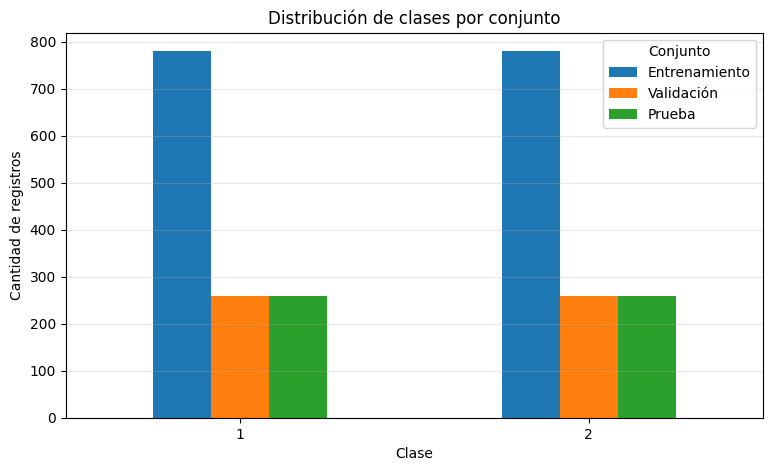

In [21]:
# Crear gráfica comparativa

distribucion = pd.DataFrame({
    "Entrenamiento": y_train.value_counts(),
    "Validación": y_val.value_counts(),
    "Prueba": y_test.value_counts()
})

distribucion = distribucion.sort_index()

distribucion.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribución de clases por conjunto")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.legend(title="Conjunto")
plt.grid(axis="y", alpha=0.3)

plt.show()

¿Por qué hacemos esta división?

Porque necesitamos evitar que el algoritmo genético conozca anticipadamente los datos con los que mediremos su rendimiento final.

- El algoritmo genético utilizará los datos de entrenamiento y validación.

- El conjunto de prueba permanecerá separado.

- Al finalizar, utilizaremos la prueba para medir la calidad de la mejor solución encontrada.

 # PARTE 5. Función de evaluación (Fitness)

5.1. ¿Qué es Fitness?

En un algoritmo genético, Fitness es la función que determina qué tan buena es una solución.

En nuestro proyecto, cada individuo representa una posible selección de las 500 características de Madelon.

5.2. Definir el modelo de clasificación

Utilizaremos RandomForestClassifier para evaluar las características seleccionadas.

In [22]:
# Modelo de clasificación
def crear_modelo():

    modelo = RandomForestClassifier(
        n_estimators=50,
        random_state=SEED,
        n_jobs=1
    )

    return modelo

¿Por qué utilizamos Random Forest?

Porque permite clasificar los registros utilizando múltiples árboles de decisión y evaluar qué tan bien funciona una selección de características.

Establecemos n_jobs=1 para evitar que Random Forest utilice paralelismo interno. Así podremos medir el paralelismo del algoritmo genético sin mezclar ambos niveles.

5.3. Crear la función Fitness

In [23]:
# Función de evaluación Fitness

def evaluar_fitness(individuo):

    # Identificar las características seleccionadas
    seleccionadas = np.where(individuo == 1)[0]

    # Evitar individuos sin características
    if len(seleccionadas) == 0:
        return 0, 0, 0

    # Seleccionar columnas de entrenamiento y validación
    X_train_sel = X_train.iloc[:, seleccionadas]
    X_val_sel = X_val.iloc[:, seleccionadas]

    # Crear modelo
    modelo = crear_modelo()

    # Entrenar modelo
    modelo.fit(X_train_sel, y_train)

    # Realizar predicciones
    predicciones = modelo.predict(X_val_sel)

    # Calcular precisión
    accuracy = accuracy_score(y_val, predicciones)

    # Calcular penalización
    penalizacion = 0.05 * (
        len(seleccionadas) / X.shape[1]
    )

    # Calcular Fitness
    fitness = accuracy - penalizacion

    return fitness, accuracy, len(seleccionadas)

5.4. Probar la función Fitness

In [24]:
# Crear individuo de prueba
individuo_prueba = np.zeros(X.shape[1], dtype=int)

# Seleccionar 50 características aleatorias
indices = np.random.choice(
    X.shape[1],
    size=50,
    replace=False
)

individuo_prueba[indices] = 1

# Evaluar individuo
fitness, accuracy, cantidad = evaluar_fitness(
    individuo_prueba
)

print("EVALUACIÓN DEL INDIVIDUO")
print("------------------------")

print("Fitness:", round(fitness, 4))
print("Accuracy:", round(accuracy, 4))
print("Características seleccionadas:", cantidad)

EVALUACIÓN DEL INDIVIDUO
------------------------
Fitness: 0.5758
Accuracy: 0.5808
Características seleccionadas: 50


5.5. Interpretar los resultados

Fitness	Calidad general de la solución considerando precisión y penalización.

Accuracy	Porcentaje de clasificaciones correctas.

Características seleccionadas	Número de variables utilizadas por el modelo.

# PARTE 6. Inicialización de la población

6.1. ¿Qué es una población?
En un algoritmo genético, una población es un conjunto de individuos que representan posibles soluciones al problema.

En nuestro proyecto:
- Cada individuo representa una selección de características.
- Cada individuo tendrá 500 posiciones.
- Cada posición representa una característica de Madelon.
- El valor 1 indica que la característica fue seleccionada.
- El valor 0 indica que no fue seleccionada.

6.2. Establecer el generador aleatorio

Utilizaremos una semilla para que los experimentos puedan reproducirse.

In [25]:
# Generador aleatorio reproducible
rng = np.random.default_rng(SEED)

print("Generador aleatorio configurado correctamente.")

Generador aleatorio configurado correctamente.


6.3. Crear la función de inicialización

Generaremos una población de 12 individuos.

Para comenzar, cada característica tendrá una probabilidad del 10 % de ser seleccionada. Esto nos permitirá iniciar con soluciones relativamente reducidas, en lugar de seleccionar aproximadamente la mitad de las 500 características.

In [26]:
# Función para inicializar la población

def inicializar_poblacion(
    tamano_poblacion,
    numero_caracteristicas,
    probabilidad=0.10,
    rng=None
):

    if rng is None:
        rng = np.random.default_rng(SEED)

    poblacion = []

    for i in range(tamano_poblacion):

        # Generar individuo aleatorio
        individuo = rng.binomial(
            1,
            probabilidad,
            size=numero_caracteristicas
        )

        # Evitar individuos sin características
        if np.sum(individuo) == 0:
            posicion = rng.integers(numero_caracteristicas)
            individuo[posicion] = 1

        poblacion.append(individuo)

    return np.array(poblacion)

6.4. Generar la población inicial

Ahora utilizaremos nuestra función para crear los individuos.

In [27]:
# Crear población inicial

poblacion = inicializar_poblacion(
    tamano_poblacion=TAMANO_POBLACION,
    numero_caracteristicas=X.shape[1],
    probabilidad=0.10,
    rng=rng
)

print("POBLACIÓN INICIAL GENERADA")
print("--------------------------")

print("Cantidad de individuos:", len(poblacion))
print("Características por individuo:", poblacion.shape[1])
print("Dimensiones de la población:", poblacion.shape)

POBLACIÓN INICIAL GENERADA
--------------------------
Cantidad de individuos: 12
Características por individuo: 500
Dimensiones de la población: (12, 500)


6.5. Visualizar los individuos

Vamos a observar cómo quedaron representados los primeros individuos.

In [28]:
# Mostrar los primeros cinco individuos

print("PRIMEROS CINCO INDIVIDUOS")
print("-------------------------")

for i in range(5):

    print(f"\nIndividuo {i + 1}:")
    print(poblacion[i][:30])

    print(
        "Características seleccionadas:",
        np.sum(poblacion[i])
    )

PRIMEROS CINCO INDIVIDUOS
-------------------------

Individuo 1:
[0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]
Características seleccionadas: 45

Individuo 2:
[0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0]
Características seleccionadas: 53

Individuo 3:
[0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0]
Características seleccionadas: 56

Individuo 4:
[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
Características seleccionadas: 55

Individuo 5:
[0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Características seleccionadas: 47


6.6. Calcular las características seleccionadas por individuo

In [29]:
# Contar características seleccionadas

caracteristicas_por_individuo = np.sum(
    poblacion,
    axis=1
)

tabla_poblacion = pd.DataFrame({
    "Individuo": np.arange(1, TAMANO_POBLACION + 1),
    "Caracteristicas_seleccionadas": caracteristicas_por_individuo
})

tabla_poblacion

,Individuo,Caracteristicas_seleccionadas
0,1,45
1,2,53
2,3,56
3,4,55
4,5,47
5,6,50
6,7,52
7,8,51
8,9,46
9,10,38


6.7. Visualizar la población inicial

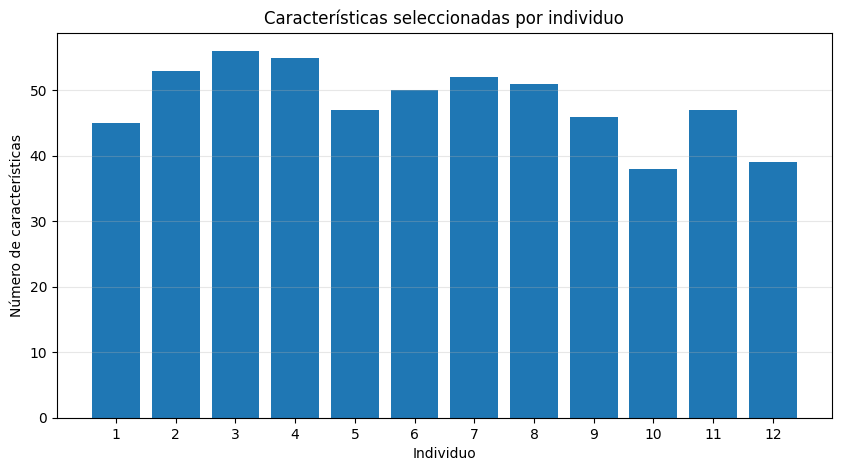

In [30]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabla_poblacion["Individuo"],
    tabla_poblacion["Caracteristicas_seleccionadas"]
)

plt.title("Características seleccionadas por individuo")
plt.xlabel("Individuo")
plt.ylabel("Número de características")
plt.xticks(range(1, TAMANO_POBLACION + 1))
plt.grid(axis="y", alpha=0.3)

plt.show()

6.8. Evaluar la población inicial

Por último, vamos a evaluar cada individuo utilizando nuestra función Fitness de la parte anterior.

Esto nos permitirá conocer qué tan buenas son las soluciones iniciales antes de aplicar selección, cruza y mutación.

In [31]:
# Evaluar todos los individuos de la población inicial

resultados_poblacion = []

for i, individuo in enumerate(poblacion):

    fitness, accuracy, cantidad = evaluar_fitness(individuo)

    resultados_poblacion.append({
        "Individuo": i + 1,
        "Fitness": fitness,
        "Accuracy": accuracy,
        "Caracteristicas": cantidad
    })

# Crear tabla de resultados
df_poblacion = pd.DataFrame(resultados_poblacion)

# Ordenar de mejor a peor Fitness
df_poblacion = df_poblacion.sort_values(
    by="Fitness",
    ascending=False
).reset_index(drop=True)

df_poblacion

,Individuo,Fitness,Accuracy,Caracteristicas
0,11,0.602992,0.607692,47
1,12,0.596100,0.600000,39
2,8,0.542977,0.548077,51
3,1,0.516654,0.521154,45
4,10,0.513508,0.517308,38
5,7,0.512108,0.517308,52
6,9,0.510785,0.515385,46
7,6,0.510385,0.515385,50
8,5,0.501069,0.505769,47
9,3,0.496323,0.501923,56


6.9. Identificar el mejor individuo inicial

In [32]:
# Obtener el mejor individuo de la población

mejor_indice = df_poblacion.loc[0, "Individuo"] - 1

mejor_individuo_inicial = poblacion[int(mejor_indice)]

print("MEJOR INDIVIDUO INICIAL")
print("-----------------------")

print("Fitness:", round(df_poblacion.loc[0, "Fitness"], 4))
print("Accuracy:", round(df_poblacion.loc[0, "Accuracy"], 4))

print(
    "Características seleccionadas:",
    int(df_poblacion.loc[0, "Caracteristicas"])
)

MEJOR INDIVIDUO INICIAL
-----------------------
Fitness: 0.603
Accuracy: 0.6077
Características seleccionadas: 47


# PARTE 7. Selección de individuos

7.1. ¿Qué es la selección?

La selección es el proceso mediante el cual el algoritmo genético elige qué individuos tendrán mayores oportunidades de reproducirse.

En nuestro proyecto utilizaremos el método de selección por torneo.

Este método funciona así:
1. Seleccionamos aleatoriamente tres individuos.
2. Comparamos sus valores de Fitness.
3. Elegimos al individuo con el Fitness más alto.
4. Repetimos el proceso hasta obtener los padres necesarios.
Los individuos con mejores resultados tendrán mayores probabilidades de transmitir sus características a las siguientes generaciones.

7.2. Crear la función de selección por torneo

In [33]:
# Función de selección por torneo

def seleccion_torneo(poblacion, fitness, tamano_torneo=3, rng=None):

    if rng is None:
        rng = np.random.default_rng(SEED)

    # Seleccionar índices aleatorios
    participantes = rng.choice(
        len(poblacion),
        size=tamano_torneo,
        replace=False
    )

    # Obtener Fitness de los participantes
    fitness_participantes = fitness[participantes]

    # Identificar al ganador
    ganador = participantes[np.argmax(fitness_participantes)]

    return poblacion[ganador].copy()

7.3. Obtener los valores Fitness de la población

In [34]:
# Evaluar Fitness de cada individuo

fitness_poblacion = np.array([
    evaluar_fitness(individuo)[0]
    for individuo in poblacion
])

print("FITNESS DE LA POBLACIÓN")
print("-----------------------")

for i, fitness in enumerate(fitness_poblacion):

    print(
        f"Individuo {i + 1}: {fitness:.4f}"
    )

FITNESS DE LA POBLACIÓN
-----------------------
Individuo 1: 0.5167
Individuo 2: 0.4851
Individuo 3: 0.4963
Individuo 4: 0.4868
Individuo 5: 0.5011
Individuo 6: 0.5104
Individuo 7: 0.5121
Individuo 8: 0.5430
Individuo 9: 0.5108
Individuo 10: 0.5135
Individuo 11: 0.6030
Individuo 12: 0.5961


7.4. Probar la selección por torneo

Vamos a realizar una prueba para comprobar que nuestra función selecciona correctamente a los individuos.

In [35]:
# Crear generador aleatorio para selección
rng_seleccion = np.random.default_rng(SEED + 1)

# Realizar un torneo
padre = seleccion_torneo(
    poblacion,
    fitness_poblacion,
    tamano_torneo=TAMANO_TORNEO,
    rng=rng_seleccion
)

print("RESULTADO DE LA SELECCIÓN")
print("-------------------------")

print("Características seleccionadas:", np.sum(padre))

print(
    "Fitness del individuo seleccionado:",
    round(evaluar_fitness(padre)[0], 4)
)

RESULTADO DE LA SELECCIÓN
-------------------------
Características seleccionadas: 51
Fitness del individuo seleccionado: 0.543


7.5. Seleccionar los padres de una nueva generación

Ahora seleccionaremos 12 individuos para formar el grupo de padres.

In [36]:
# Seleccionar padres para reproducción

def seleccionar_padres(
    poblacion,
    fitness,
    cantidad_padres,
    tamano_torneo=3,
    rng=None
):

    padres = []

    for _ in range(cantidad_padres):

        padre = seleccion_torneo(
            poblacion,
            fitness,
            tamano_torneo,
            rng
        )

        padres.append(padre)

    return np.array(padres)

In [37]:
# Generar grupo de padres

rng_seleccion = np.random.default_rng(SEED + 2)

padres = seleccionar_padres(
    poblacion,
    fitness_poblacion,
    cantidad_padres=TAMANO_POBLACION,
    tamano_torneo=TAMANO_TORNEO,
    rng=rng_seleccion
)

print("GRUPO DE PADRES")
print("----------------")

print("Cantidad de padres:", len(padres))
print("Dimensiones:", padres.shape)

GRUPO DE PADRES
----------------
Cantidad de padres: 12
Dimensiones: (12, 500)


7.6. Comparar la población original con los padres seleccionados

In [38]:
# Comparar cantidad de características

comparacion_seleccion = pd.DataFrame({
    "Individuo_original": np.sum(poblacion, axis=1),
    "Padres_seleccionados": np.sum(padres, axis=1)
})

comparacion_seleccion

,Individuo_original,Padres_seleccionados
0,45,38
1,53,39
2,56,47
3,55,46
4,47,47
5,50,47
6,52,51
7,51,38
8,46,38
9,38,51


# PARTE 8. Cruza (Crossover)

8.1. ¿Qué es la cruza?

La cruza es el proceso mediante el cual combinamos dos padres para crear nuevos individuos.

En nuestro proyecto utilizaremos cruza de un punto (Single-Point Crossover).

El procedimiento es:
1. Seleccionar dos padres.
2. Elegir una posición aleatoria entre sus 500 características.
3. Dividir ambos individuos en esa posición.
4. Intercambiar sus segmentos.
5. Generar dos hijos.

8.2. Crear la función de cruza

In [39]:
# Función de cruza de un punto

def cruza(padre1, padre2, rng=None):

    if rng is None:
        rng = np.random.default_rng(SEED)

    # Elegir punto de cruza
    punto = rng.integers(1, len(padre1))

    # Generar descendientes
    hijo1 = np.concatenate([
        padre1[:punto],
        padre2[punto:]
    ])

    hijo2 = np.concatenate([
        padre2[:punto],
        padre1[punto:]
    ])

    return hijo1, hijo2

8.3. Probar la cruza con dos padres

In [40]:
# Crear generador aleatorio
rng_cruza = np.random.default_rng(SEED + 3)

# Seleccionar dos padres
padre1 = padres[0]
padre2 = padres[1]

# Aplicar cruza
hijo1, hijo2 = cruza(
    padre1,
    padre2,
    rng_cruza
)

print("RESULTADOS DE LA CRUZA")
print("----------------------")

print("Características del padre 1:", np.sum(padre1))
print("Características del padre 2:", np.sum(padre2))

print("\nCaracterísticas del hijo 1:", np.sum(hijo1))
print("Características del hijo 2:", np.sum(hijo2))

print("\nDimensión del hijo 1:", hijo1.shape)
print("Dimensión del hijo 2:", hijo2.shape)

RESULTADOS DE LA CRUZA
----------------------
Características del padre 1: 38
Características del padre 2: 39

Características del hijo 1: 40
Características del hijo 2: 37

Dimensión del hijo 1: (500,)
Dimensión del hijo 2: (500,)


8.4. Visualizar padres e hijos

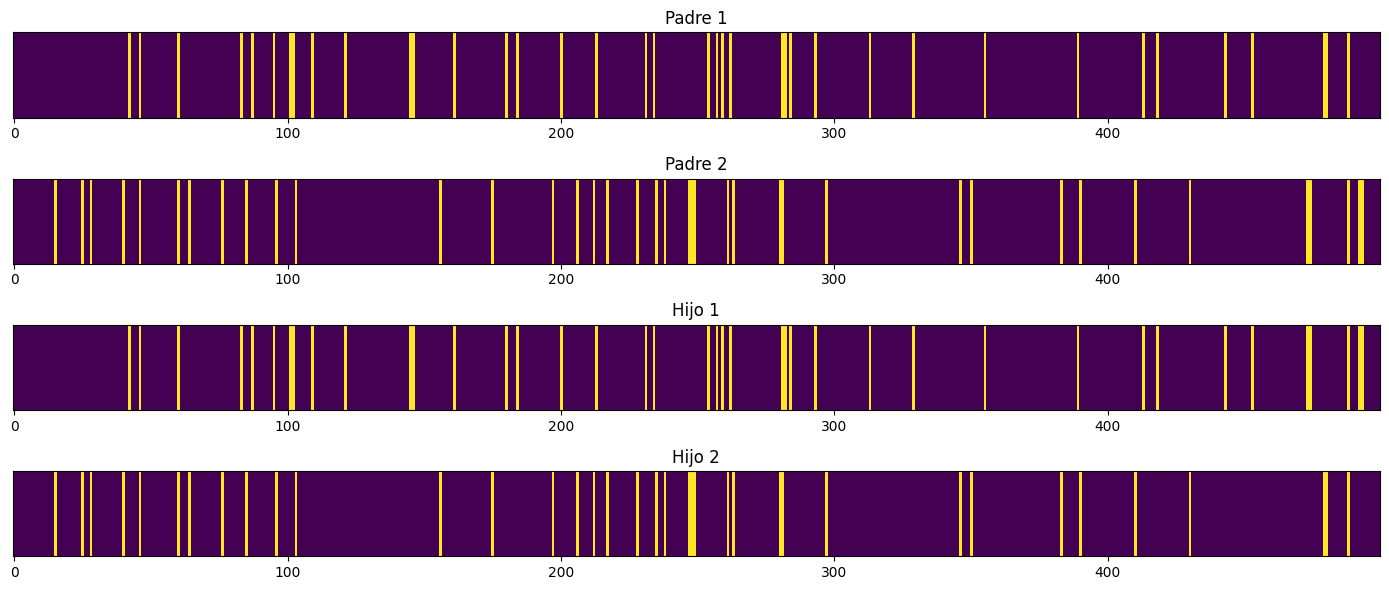

In [41]:
# Comparación visual de padres e hijos

fig, axes = plt.subplots(4, 1, figsize=(14, 6))

individuos = [
    padre1,
    padre2,
    hijo1,
    hijo2
]

nombres = [
    "Padre 1",
    "Padre 2",
    "Hijo 1",
    "Hijo 2"
]

for ax, individuo, nombre in zip(
    axes,
    individuos,
    nombres
):

    ax.imshow(
        individuo.reshape(1, -1),
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_title(nombre)
    ax.set_yticks([])

plt.tight_layout()
plt.show()

8.5. Crear una función para cruzar toda la población

Ahora necesitamos aplicar la cruza a los 12 padres y generar una nueva población de 12 hijos.

In [42]:
# Crear nueva población mediante cruza

def generar_descendientes(padres, rng=None):

    if rng is None:
        rng = np.random.default_rng(SEED)

    descendientes = []

    for i in range(0, len(padres), 2):

        padre1 = padres[i]
        padre2 = padres[i + 1]

        hijo1, hijo2 = cruza(
            padre1,
            padre2,
            rng
        )

        descendientes.append(hijo1)
        descendientes.append(hijo2)

    return np.array(descendientes)

In [43]:
# Generar descendientes

rng_cruza = np.random.default_rng(SEED + 4)

nueva_poblacion = generar_descendientes(
    padres,
    rng_cruza
)

print("NUEVA POBLACIÓN")
print("----------------")

print("Cantidad de individuos:", len(nueva_poblacion))
print("Dimensiones:", nueva_poblacion.shape)

NUEVA POBLACIÓN
----------------
Cantidad de individuos: 12
Dimensiones: (12, 500)


8.6. Comparar la cantidad de características

In [44]:
# Comparar padres e hijos

comparacion_cruza = pd.DataFrame({
    "Padre": np.arange(1, len(padres) + 1),
    "Caracteristicas_padre": np.sum(padres, axis=1),
    "Caracteristicas_hijo": np.sum(nueva_poblacion, axis=1)
})

comparacion_cruza

,Padre,Caracteristicas_padre,Caracteristicas_hijo
0,1,38,35
1,2,39,42
2,3,47,47
3,4,46,46
4,5,47,47
5,6,47,47
6,7,51,42
7,8,38,47
8,9,38,48
9,10,51,41


# Parte 9. Mutación

Ahora implementaremos la mutación. Esta operación introduce pequeños cambios aleatorios en los individuos para mantener la diversidad genética y evitar que el algoritmo se estanque en soluciones poco eficientes.

En nuestro caso, cada característica tiene una probabilidad del 1 % de cambiar:
- Si tiene valor 0, cambia a 1.
- Si tiene valor 1, cambia a 0.

Función de mutación

In [45]:
def mutar(individuo, probabilidad_mutacion=PROB_MUTACION, rng=None):

    if rng is None:
        rng = np.random.default_rng(SEED)

    individuo_mutado = individuo.copy()

    mascara = rng.random(len(individuo_mutado)) < probabilidad_mutacion

    individuo_mutado[mascara] = 1 - individuo_mutado[mascara]

    return individuo_mutado

Probar la mutación

In [46]:
rng_mutacion = np.random.default_rng(SEED + 5)

individuo_original = nueva_poblacion[0]

individuo_mutado = mutar(
    individuo_original,
    PROB_MUTACION,
    rng_mutacion
)

print("RESULTADOS DE LA MUTACIÓN")
print("-------------------------")

print("Características originales:", np.sum(individuo_original))
print("Características después de mutar:", np.sum(individuo_mutado))

print("Dimensión original:", individuo_original.shape)
print("Dimensión mutada:", individuo_mutado.shape)

print("Genes modificados:", np.sum(individuo_original != individuo_mutado))

RESULTADOS DE LA MUTACIÓN
-------------------------
Características originales: 35
Características después de mutar: 40
Dimensión original: (500,)
Dimensión mutada: (500,)
Genes modificados: 5


Aplicar mutación a toda la población

In [47]:
def mutar_poblacion(poblacion, probabilidad_mutacion=PROB_MUTACION, rng=None):

    if rng is None:
        rng = np.random.default_rng(SEED)

    poblacion_mutada = np.array([
        mutar(individuo, probabilidad_mutacion, rng)
        for individuo in poblacion
    ])

    return poblacion_mutada


rng_mutacion = np.random.default_rng(SEED + 6)

poblacion_mutada = mutar_poblacion(
    nueva_poblacion,
    PROB_MUTACION,
    rng_mutacion
)

print("POBLACIÓN DESPUÉS DE LA MUTACIÓN")
print("--------------------------------")

print("Cantidad de individuos:", len(poblacion_mutada))
print("Dimensiones:", poblacion_mutada.shape)

POBLACIÓN DESPUÉS DE LA MUTACIÓN
--------------------------------
Cantidad de individuos: 12
Dimensiones: (12, 500)


Comparar antes y después

In [48]:
comparacion_mutacion = pd.DataFrame({
    "Individuo": np.arange(1, len(nueva_poblacion) + 1),
    "Antes_mutacion": np.sum(nueva_poblacion, axis=1),
    "Despues_mutacion": np.sum(poblacion_mutada, axis=1),
    "Genes_modificados": np.sum(
        nueva_poblacion != poblacion_mutada,
        axis=1
    )
})

comparacion_mutacion

,Individuo,Antes_mutacion,Despues_mutacion,Genes_modificados
0,1,35,39,4
1,2,42,47,7
2,3,47,49,4
3,4,46,51,5
4,5,47,49,2
5,6,47,49,4
6,7,42,46,4
7,8,47,51,4
8,9,48,51,3
9,10,41,46,7


Parte 10. Elitismo

El elitismo consiste en conservar directamente a los mejores individuos de una generación para evitar que sus buenas soluciones se pierdan durante la cruza y la mutación.


Función de elitismo

In [49]:
def aplicar_elitismo(poblacion_anterior, fitness_anterior,
                     poblacion_nueva, cantidad_elite=ELITISMO):

    mejores_indices = np.argsort(fitness_anterior)[::-1]

    elite = poblacion_anterior[mejores_indices[:cantidad_elite]]

    poblacion_final = poblacion_nueva.copy()

    poblacion_final[:cantidad_elite] = elite

    return poblacion_final, elite

Probar el elitismo

Primero evaluaremos la población que teníamos antes de la cruza y mutación:

In [50]:
fitness_anterior = np.array([
    evaluar_fitness(individuo)[0]
    for individuo in poblacion
])

In [51]:
poblacion_final, mejores_individuos = aplicar_elitismo(
    poblacion,
    fitness_anterior,
    poblacion_mutada,
    ELITISMO
)

print("RESULTADOS DEL ELITISMO")
print("-----------------------")

print("Individuos conservados:", len(mejores_individuos))
print("Cantidad de individuos finales:", len(poblacion_final))
print("Dimensiones de la población final:", poblacion_final.shape)

RESULTADOS DEL ELITISMO
-----------------------
Individuos conservados: 2
Cantidad de individuos finales: 12
Dimensiones de la población final: (12, 500)


Verificar que los mejores individuos se conservaron

In [52]:
print("VERIFICACIÓN DE ELITISMO")
print("------------------------")

for i in range(ELITISMO):
    iguales = np.array_equal(
        poblacion_final[i],
        mejores_individuos[i]
    )

    print(f"Individuo élite {i+1} conservado: {iguales}")

VERIFICACIÓN DE ELITISMO
------------------------
Individuo élite 1 conservado: True
Individuo élite 2 conservado: True


Evaluar la población final

In [53]:
resultados_finales = [
    evaluar_fitness(individuo)
    for individuo in poblacion_final
]

tabla_final = pd.DataFrame(
    resultados_finales,
    columns=["Fitness", "Accuracy", "Caracteristicas"]
)

tabla_final.index = np.arange(1, len(tabla_final) + 1)

tabla_final

,Fitness,Accuracy,Caracteristicas
1,0.602992,0.607692,47
2,0.596100,0.600000,39
3,0.545100,0.550000,49
4,0.546823,0.551923,51
5,0.585485,0.590385,49
6,0.622023,0.626923,49
7,0.520400,0.525000,46
8,0.587208,0.592308,51
9,0.494900,0.500000,51
10,0.578092,0.582692,46


# Parte 11. Integración del algoritmo genético secuencial

Ahora vamos a integrar todos los componentes que ya desarrollamos:
1. Inicialización de la población.
2. Evaluación de fitness.
3. Selección por torneo.
4. Cruza de un punto.
5. Mutación.
6. Elitismo.
El objetivo es ejecutar el algoritmo durante 10 generaciones y observar cómo evoluciona la calidad de las soluciones.

Función del algoritmo genético secuencial

In [54]:
def algoritmo_genetico_secuencial(
    tamano_poblacion=TAMANO_POBLACION,
    generaciones=NUM_GENERACIONES,
    prob_mutacion=PROB_MUTACION,
    cantidad_elite=ELITISMO,
    semilla=SEED
):

    rng = np.random.default_rng(semilla)

    # 1. Inicializar población
    poblacion_actual = inicializar_poblacion(
        tamano_poblacion,
        X.shape[1],
        rng=rng
    )

    historial = []

    # Evolución
    for generacion in range(generaciones):

        # 2. Evaluar fitness
        resultados = [
            evaluar_fitness(individuo)
            for individuo in poblacion_actual
        ]

        fitness = np.array([r[0] for r in resultados])

        mejor_indice = np.argmax(fitness)

        historial.append({
            "Generacion": generacion + 1,
            "Mejor_fitness": fitness[mejor_indice],
            "Accuracy": resultados[mejor_indice][1],
            "Caracteristicas": resultados[mejor_indice][2]
        })

        # 3. Selección
        padres = seleccionar_padres(
            poblacion_actual,
            fitness,
            tamano_poblacion,
            TAMANO_TORNEO,
            rng
        )

        # 4. Cruza
        descendientes = generar_descendientes(
            padres,
            rng
        )

        # 5. Mutación
        descendientes = mutar_poblacion(
            descendientes,
            prob_mutacion,
            rng
        )

        # 6. Elitismo
        poblacion_actual, elite = aplicar_elitismo(
            poblacion_actual,
            fitness,
            descendientes,
            cantidad_elite
        )

    # Evaluar población final
    resultados_finales = [
        evaluar_fitness(individuo)
        for individuo in poblacion_actual
    ]

    fitness_final = np.array([r[0] for r in resultados_finales])

    mejor_final = np.argmax(fitness_final)

    historial.append({
        "Generacion": generaciones + 1,
        "Mejor_fitness": fitness_final[mejor_final],
        "Accuracy": resultados_finales[mejor_final][1],
        "Caracteristicas": resultados_finales[mejor_final][2]
    })

    return poblacion_actual, pd.DataFrame(historial)

Ejecutar el algoritmo

In [55]:
inicio = time.time()

poblacion_secuencial, historial_secuencial = algoritmo_genetico_secuencial()

tiempo_secuencial = time.time() - inicio

print("RESULTADOS DEL ALGORITMO GENÉTICO SECUENCIAL")
print("--------------------------------------------")

print("Tiempo de ejecución:", round(tiempo_secuencial, 2), "segundos")
print("Dimensiones de la población:", poblacion_secuencial.shape)

historial_secuencial

RESULTADOS DEL ALGORITMO GENÉTICO SECUENCIAL
--------------------------------------------
Tiempo de ejecución: 34.5 segundos
Dimensiones de la población: (12, 500)


,Generacion,Mejor_fitness,Accuracy,Caracteristicas
0,1,0.602992,0.607692,47
1,2,0.622923,0.626923,40
2,3,0.664031,0.669231,52
3,4,0.672946,0.678846,59
4,5,0.681138,0.686538,54
5,6,0.681138,0.686538,54
6,7,0.707362,0.713462,61
7,8,0.714454,0.721154,67
8,9,0.719623,0.726923,73
9,10,0.719623,0.726923,73


Visualizar la evolución del fitness

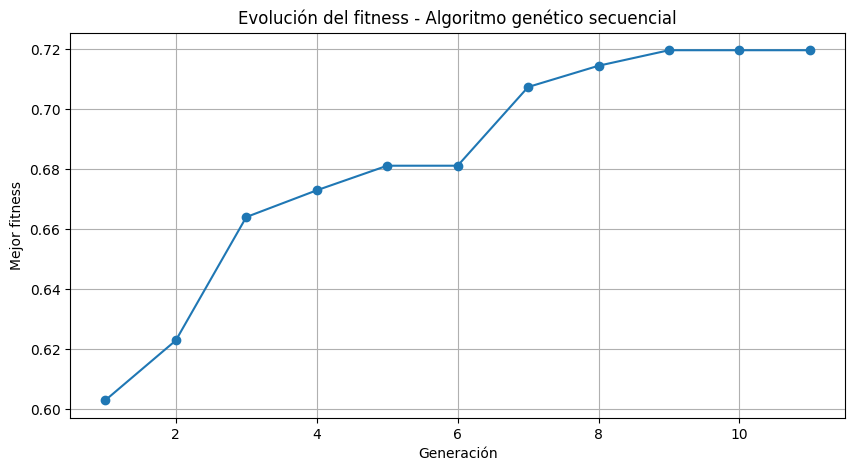

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(
    historial_secuencial["Generacion"],
    historial_secuencial["Mejor_fitness"],
    marker="o"
)

plt.title("Evolución del fitness - Algoritmo genético secuencial")
plt.xlabel("Generación")
plt.ylabel("Mejor fitness")
plt.grid(True)

plt.show()

Mostrar la mejor solución encontrada

In [57]:
mejor_fitness = historial_secuencial["Mejor_fitness"].max()

mejor_generacion = historial_secuencial.loc[
    historial_secuencial["Mejor_fitness"].idxmax()
]

print("MEJOR SOLUCIÓN ENCONTRADA")
print("-------------------------")

print("Generación:", int(mejor_generacion["Generacion"]))
print("Fitness:", round(mejor_generacion["Mejor_fitness"], 6))
print("Accuracy:", round(mejor_generacion["Accuracy"], 6))
print("Características seleccionadas:", int(mejor_generacion["Caracteristicas"]))
print("Tiempo total:", round(tiempo_secuencial, 2), "segundos")

MEJOR SOLUCIÓN ENCONTRADA
-------------------------
Generación: 9
Fitness: 0.719623
Accuracy: 0.726923
Características seleccionadas: 73
Tiempo total: 34.5 segundos


# Parte 12. Evaluación paralela con Joblib

Ahora comenzaremos la implementación paralela. En esta etapa distribuiremos la evaluación de los individuos entre varios procesos.

La idea es que, en lugar de evaluar los 12 individuos uno por uno, varios procesos puedan evaluar individuos diferentes al mismo tiempo.

Evaluación paralela de la población

In [58]:
def evaluar_poblacion_paralela(poblacion, n_jobs=2):

    resultados = Parallel(n_jobs=n_jobs)(
        delayed(evaluar_fitness)(individuo)
        for individuo in poblacion
    )

    return resultados

In [59]:
inicio = time.time()

resultados_paralelos = evaluar_poblacion_paralela(
    poblacion,
    n_jobs=2
)

tiempo_evaluacion_paralela = time.time() - inicio

print("EVALUACIÓN PARALELA")
print("-------------------")

print("Individuos evaluados:", len(resultados_paralelos))
print("Procesos utilizados:", 2)
print("Tiempo:", round(tiempo_evaluacion_paralela, 2), "segundos")

EVALUACIÓN PARALELA
-------------------
Individuos evaluados: 12
Procesos utilizados: 2
Tiempo: 3.48 segundos


Comparar evaluación secuencial y paralela

In [60]:
inicio = time.time()

resultados_secuenciales = [
    evaluar_fitness(individuo)
    for individuo in poblacion
]

tiempo_evaluacion_secuencial = time.time() - inicio

inicio = time.time()

resultados_paralelos = evaluar_poblacion_paralela(
    poblacion,
    n_jobs=2
)

tiempo_evaluacion_paralela = time.time() - inicio

comparacion_evaluacion = pd.DataFrame({
    "Metodo": ["Secuencial", "Paralelo (2 procesos)"],
    "Tiempo_segundos": [
        tiempo_evaluacion_secuencial,
        tiempo_evaluacion_paralela
    ]
})

comparacion_evaluacion

,Metodo,Tiempo_segundos
0,Secuencial,3.195682
1,Paralelo (2 procesos),2.609211


In [61]:
print("VERIFICACIÓN DE RESULTADOS")
print("--------------------------")

for i, (sec, par) in enumerate(
    zip(resultados_secuenciales, resultados_paralelos)
):
    iguales = np.allclose(sec, par)

    print(f"Individuo {i+1}: {iguales}")

VERIFICACIÓN DE RESULTADOS
--------------------------
Individuo 1: True
Individuo 2: True
Individuo 3: True
Individuo 4: True
Individuo 5: True
Individuo 6: True
Individuo 7: True
Individuo 8: True
Individuo 9: True
Individuo 10: True
Individuo 11: True
Individuo 12: True


# Parte 13. Algoritmo genético paralelo completo

Ahora integraremos Joblib en el algoritmo genético. La diferencia principal será que la evaluación de fitness se realizará mediante varios procesos.

Crear el algoritmo paralelo

In [62]:
def algoritmo_genetico_paralelo(
    tamano_poblacion=TAMANO_POBLACION,
    generaciones=NUM_GENERACIONES,
    prob_mutacion=PROB_MUTACION,
    cantidad_elite=ELITISMO,
    semilla=SEED,
    n_jobs=2
):

    rng = np.random.default_rng(semilla)

    # 1. Inicializar población
    poblacion_actual = inicializar_poblacion(
        tamano_poblacion,
        X.shape[1],
        rng=rng
    )

    historial = []

    for generacion in range(generaciones):

        # 2. Evaluar fitness en paralelo
        resultados = evaluar_poblacion_paralela(
            poblacion_actual,
            n_jobs=n_jobs
        )

        fitness = np.array([r[0] for r in resultados])

        mejor_indice = np.argmax(fitness)

        historial.append({
            "Generacion": generacion + 1,
            "Mejor_fitness": fitness[mejor_indice],
            "Accuracy": resultados[mejor_indice][1],
            "Caracteristicas": resultados[mejor_indice][2]
        })

        # 3. Selección
        padres = seleccionar_padres(
            poblacion_actual,
            fitness,
            tamano_poblacion,
            TAMANO_TORNEO,
            rng
        )

        # 4. Cruza
        descendientes = generar_descendientes(
            padres,
            rng
        )

        # 5. Mutación
        descendientes = mutar_poblacion(
            descendientes,
            prob_mutacion,
            rng
        )

        # 6. Elitismo
        poblacion_actual, elite = aplicar_elitismo(
            poblacion_actual,
            fitness,
            descendientes,
            cantidad_elite
        )

    # Evaluación final en paralelo
    resultados_finales = evaluar_poblacion_paralela(
        poblacion_actual,
        n_jobs=n_jobs
    )

    fitness_final = np.array([r[0] for r in resultados_finales])

    mejor_indice = np.argmax(fitness_final)

    historial.append({
        "Generacion": generaciones + 1,
        "Mejor_fitness": fitness_final[mejor_indice],
        "Accuracy": resultados_finales[mejor_indice][1],
        "Caracteristicas": resultados_finales[mejor_indice][2]
    })

    return poblacion_actual, pd.DataFrame(historial)

Ejecutar el algoritmo paralelo

In [63]:
inicio = time.time()

poblacion_paralela, historial_paralelo = algoritmo_genetico_paralelo(
    n_jobs=2
)

tiempo_paralelo = time.time() - inicio

print("RESULTADOS DEL ALGORITMO GENÉTICO PARALELO")
print("------------------------------------------")

print("Procesos utilizados:", 2)
print("Tiempo de ejecución:", round(tiempo_paralelo, 2), "segundos")
print("Dimensiones:", poblacion_paralela.shape)

historial_paralelo

RESULTADOS DEL ALGORITMO GENÉTICO PARALELO
------------------------------------------
Procesos utilizados: 2
Tiempo de ejecución: 30.04 segundos
Dimensiones: (12, 500)


,Generacion,Mejor_fitness,Accuracy,Caracteristicas
0,1,0.602992,0.607692,47
1,2,0.622923,0.626923,40
2,3,0.664031,0.669231,52
3,4,0.672946,0.678846,59
4,5,0.681138,0.686538,54
5,6,0.681138,0.686538,54
6,7,0.707362,0.713462,61
7,8,0.714454,0.721154,67
8,9,0.719623,0.726923,73
9,10,0.719623,0.726923,73


Comparar ambos algoritmos

In [64]:
comparacion_algoritmos = pd.DataFrame({
    "Metodo": ["Secuencial", "Paralelo (2 procesos)"],
    "Tiempo_segundos": [
        tiempo_secuencial,
        tiempo_paralelo
    ],
    "Mejor_fitness": [
        historial_secuencial["Mejor_fitness"].max(),
        historial_paralelo["Mejor_fitness"].max()
    ],
    "Mejor_accuracy": [
        historial_secuencial["Accuracy"].max(),
        historial_paralelo["Accuracy"].max()
    ]
})

comparacion_algoritmos

,Metodo,Tiempo_segundos,Mejor_fitness,Mejor_accuracy
0,Secuencial,34.502503,0.719623,0.726923
1,Paralelo (2 procesos),30.041010,0.719623,0.726923


Calcular aceleración y eficiencia

In [65]:
speedup = tiempo_secuencial / tiempo_paralelo

eficiencia = (speedup / 2) * 100

print("MÉTRICAS DE RENDIMIENTO")
print("----------------------")

print("Speedup:", round(speedup, 4))
print("Eficiencia:", round(eficiencia, 2), "%")
print("Reducción de tiempo:",
      round((1 - tiempo_paralelo / tiempo_secuencial) * 100, 2), "%")

MÉTRICAS DE RENDIMIENTO
----------------------
Speedup: 1.1485
Eficiencia: 57.43 %
Reducción de tiempo: 12.93 %


# Parte 14. Experimentos con diferentes cantidades de procesos


Ahora realizaremos una de las partes más importantes del proyecto: comprobar cómo cambia el rendimiento al utilizar diferentes cantidades de procesos.

Ejecutar los experimentos

In [66]:
procesos_prueba = [1, 2, 4, 8]
repeticiones = 3

resultados_experimentos = []

for n_jobs in procesos_prueba:

    for repeticion in range(repeticiones):

        semilla = SEED + repeticion

        inicio = time.time()

        poblacion_resultado, historial = algoritmo_genetico_paralelo(
            semilla=semilla,
            n_jobs=n_jobs
        )

        tiempo = time.time() - inicio

        mejor = historial.loc[
            historial["Mejor_fitness"].idxmax()
        ]

        resultados_experimentos.append({
            "Procesos": n_jobs,
            "Repeticion": repeticion + 1,
            "Tiempo": tiempo,
            "Fitness": mejor["Mejor_fitness"],
            "Accuracy": mejor["Accuracy"],
            "Caracteristicas": mejor["Caracteristicas"]
        })

        print(
            f"Procesos: {n_jobs} | "
            f"Repetición: {repeticion + 1} | "
            f"Tiempo: {tiempo:.2f} segundos"
        )

df_experimentos = pd.DataFrame(resultados_experimentos)

df_experimentos

Procesos: 1 | Repetición: 1 | Tiempo: 33.51 segundos
Procesos: 1 | Repetición: 2 | Tiempo: 33.80 segundos
Procesos: 1 | Repetición: 3 | Tiempo: 35.78 segundos
Procesos: 2 | Repetición: 1 | Tiempo: 28.53 segundos
Procesos: 2 | Repetición: 2 | Tiempo: 28.80 segundos
Procesos: 2 | Repetición: 3 | Tiempo: 29.82 segundos
Procesos: 4 | Repetición: 1 | Tiempo: 23.08 segundos
Procesos: 4 | Repetición: 2 | Tiempo: 22.56 segundos
Procesos: 4 | Repetición: 3 | Tiempo: 22.48 segundos
Procesos: 8 | Repetición: 1 | Tiempo: 21.04 segundos
Procesos: 8 | Repetición: 2 | Tiempo: 20.16 segundos
Procesos: 8 | Repetición: 3 | Tiempo: 20.14 segundos


,Procesos,Repeticion,Tiempo,Fitness,Accuracy,Caracteristicas
0,1,1,33.512306,0.719623,0.726923,73.0
1,1,2,33.798444,0.718800,0.725000,62.0
2,1,3,35.783221,0.721446,0.728846,74.0
3,2,1,28.526366,0.719623,0.726923,73.0
4,2,2,28.801885,0.718800,0.725000,62.0
5,2,3,29.822550,0.721446,0.728846,74.0
6,4,1,23.079249,0.719623,0.726923,73.0
7,4,2,22.556158,0.718800,0.725000,62.0
8,4,3,22.483255,0.721446,0.728846,74.0
9,8,1,21.039327,0.719623,0.726923,73.0


Calcular promedios y desviación estándar

In [67]:
resumen_experimentos = df_experimentos.groupby("Procesos").agg(
    Tiempo_promedio=("Tiempo", "mean"),
    Tiempo_std=("Tiempo", "std"),
    Fitness_promedio=("Fitness", "mean"),
    Fitness_std=("Fitness", "std"),
    Accuracy_promedio=("Accuracy", "mean"),
    Caracteristicas_promedio=("Caracteristicas", "mean")
).reset_index()

resumen_experimentos

,Procesos,Tiempo_promedio,Tiempo_std,Fitness_promedio,Fitness_std,Accuracy_promedio,Caracteristicas_promedio
0,1,34.364657,1.236815,0.719956,0.001354,0.726923,69.666667
1,2,29.050267,0.682857,0.719956,0.001354,0.726923,69.666667
2,4,22.706221,0.325102,0.719956,0.001354,0.726923,69.666667
3,8,20.446501,0.513437,0.719956,0.001354,0.726923,69.666667


Calcular speedup y eficiencia

Para esta comparación utilizaremos como referencia el tiempo promedio de la configuración de un proceso.

In [68]:
tiempo_base = resumen_experimentos.loc[
    resumen_experimentos["Procesos"] == 1,
    "Tiempo_promedio"
].iloc[0]

resumen_experimentos["Speedup"] = (
    tiempo_base / resumen_experimentos["Tiempo_promedio"]
)

resumen_experimentos["Eficiencia"] = (
    resumen_experimentos["Speedup"] /
    resumen_experimentos["Procesos"]
) * 100

resumen_experimentos

,Procesos,Tiempo_promedio,Tiempo_std,Fitness_promedio,Fitness_std,Accuracy_promedio,Caracteristicas_promedio,Speedup,Eficiencia
0,1,34.364657,1.236815,0.719956,0.001354,0.726923,69.666667,1.000000,100.000000
1,2,29.050267,0.682857,0.719956,0.001354,0.726923,69.666667,1.182938,59.146887
2,4,22.706221,0.325102,0.719956,0.001354,0.726923,69.666667,1.513447,37.836171
3,8,20.446501,0.513437,0.719956,0.001354,0.726923,69.666667,1.680711,21.008887


Gráfica de tiempo de ejecución

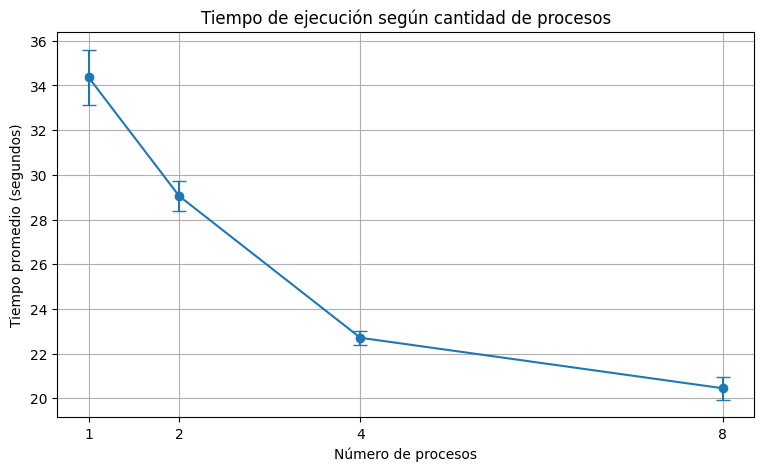

In [69]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    resumen_experimentos["Procesos"],
    resumen_experimentos["Tiempo_promedio"],
    yerr=resumen_experimentos["Tiempo_std"],
    marker="o",
    capsize=5
)

plt.title("Tiempo de ejecución según cantidad de procesos")
plt.xlabel("Número de procesos")
plt.ylabel("Tiempo promedio (segundos)")
plt.xticks(procesos_prueba)
plt.grid(True)

plt.show()

Gráfica de speedup real e ideal

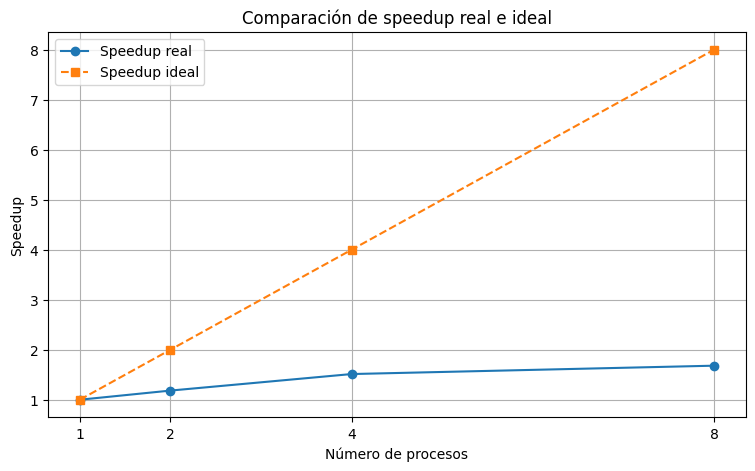

In [70]:
plt.figure(figsize=(9, 5))

plt.plot(
    resumen_experimentos["Procesos"],
    resumen_experimentos["Speedup"],
    marker="o",
    label="Speedup real"
)

plt.plot(
    resumen_experimentos["Procesos"],
    resumen_experimentos["Procesos"],
    linestyle="--",
    marker="s",
    label="Speedup ideal"
)

plt.title("Comparación de speedup real e ideal")
plt.xlabel("Número de procesos")
plt.ylabel("Speedup")
plt.xticks(procesos_prueba)
plt.grid(True)
plt.legend()

plt.show()

# Ley de Amdahl: fracción paralelizable

Calcular la fracción paralelizable

In [71]:
resumen_experimentos["Fraccion_paralelizable"] = np.where(
    resumen_experimentos["Procesos"] == 1,
    np.nan,
    (
        1 - 1 / resumen_experimentos["Speedup"]
    ) / (
        1 - 1 / resumen_experimentos["Procesos"]
    )
)

resumen_experimentos["Fraccion_paralelizable_pct"] = (
    resumen_experimentos["Fraccion_paralelizable"] * 100
)

resumen_experimentos[
    ["Procesos", "Speedup", "Eficiencia",
     "Fraccion_paralelizable_pct"]
]

,Procesos,Speedup,Eficiencia,Fraccion_paralelizable_pct
0,1,1.000000,100.000000,NaN
1,2,1.182938,59.146887,30.929394
2,4,1.513447,37.836171,45.234213
3,8,1.680711,21.008887,46.287279


Mostrar la estimación para 8 procesos

In [72]:
amdahl_8 = resumen_experimentos[
    resumen_experimentos["Procesos"] == 8
]["Fraccion_paralelizable_pct"].iloc[0]

print("ANÁLISIS DE LA LEY DE AMDAHL")
print("----------------------------")

print("Fracción paralelizable:", round(amdahl_8, 2), "%")
print("Fracción secuencial:", round(100 - amdahl_8, 2), "%")

ANÁLISIS DE LA LEY DE AMDAHL
----------------------------
Fracción paralelizable: 46.29 %
Fracción secuencial: 53.71 %


# Modelo de islas con MP

A diferencia de Joblib, donde varios procesos evalúan individuos de una misma población, el modelo de islas trabaja con poblaciones independientes:
- Cada proceso representa una isla.
- Cada isla ejecuta su propio algoritmo genético.
- Las islas evolucionan de manera independiente.
- Después de cierto número de generaciones, intercambian individuos.
- La migración permite compartir soluciones entre las islas.
Utilizaremos una topología de anillo: cada isla enviará un individuo a la siguiente y recibirá uno de la isla anterior.

In [73]:
import shutil
import importlib.util

print("VERIFICACIÓN DE MPI")
print("-------------------")

print("mpiexec:", shutil.which("mpiexec"))
print("mpirun:", shutil.which("mpirun"))
print("mpi4py instalado:", importlib.util.find_spec("mpi4py") is not None)

VERIFICACIÓN DE MPI
-------------------
mpiexec: /usr/bin/mpiexec
mpirun: /usr/bin/mpirun
mpi4py instalado: True


In [74]:
%pip install mpi4py

Note: you may need to restart the kernel to use updated packages.


In [75]:
import mpi4py
print("mpi4py:", mpi4py.__version__)

mpi4py: 4.1.2


In [76]:
from mpi4py import MPI
print("Procesos disponibles:", MPI.COMM_WORLD.Get_size())
print("Rango del proceso:", MPI.COMM_WORLD.Get_rank())

KeyboardInterrupt: 

In [77]:
import numpy as np

np.savez_compressed(
    "madelon_split.npz",
    X_train=X_train.to_numpy(),
    X_val=X_val.to_numpy(),
    y_train=y_train.to_numpy(),
    y_val=y_val.to_numpy()
)

print("Datos guardados correctamente")
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)

Datos guardados correctamente
Entrenamiento: (1560, 500)
Validación: (520, 500)
